# Лабораторная №2. Какие ветви модели можно удалить?
**Вариант 7–1–4: SMC → зануление → Колмогоров — Смирнов.**

Цель — определить, какие зависимости модели ЛР1 нужны для предсказания ускорения.
Подробная теория — в [отчёте](LAB2_REPORT.md), код — в `lab2_analysis.py`.

## 1. Модель и метод
$$a=-kx-cv+b.$$

$x$ — координата, $v$ — скорость, $a$ — ускорение; $k=\omega^2$ отвечает за пружину,
$c=2\zeta\omega$ — за сопротивление, $b$ — за смещение измерений.
Проверяем ветви **$x\to a$** и **$v\to a$** правой части уравнения.

1. **SMC:** получаем множество вероятных наборов $(k,c,b)$ вместо одной оценки.
   Частицы постепенно учитывают данные через промежуточные распределения.
2. **Зануление:** заменяем $x$ или $v$ нулём в обучающей таблице, оставляя $a$ прежним,
   и снова оцениваем параметры. Это вмешательство в данные, а не физическая остановка тележки.
3. **KS:** сравниваем распределения коэффициентов до и после вмешательства.
   $D=\sup_z|F(z)-G(z)|$: 0 — совпадение, 1 — максимальное различие ECDF.

Большой KS сам по себе не означает, что ветвь нужна: после исчезновения входа
информация о его коэффициенте теряется. Поэтому ветвь удаляем, только если одновременно:

- верхняя 95%-квантиль относительного вклада в ускорение **меньше 1%**;
- RMSE на отложенных данных после удаления выросла **не более чем на 5%**.

Это выбранные практические допуски. Проверяем две ошибки оценки параметров:
квадратичную (MSE) и абсолютную (MAE). При расхождении решений сохраняем ветвь.

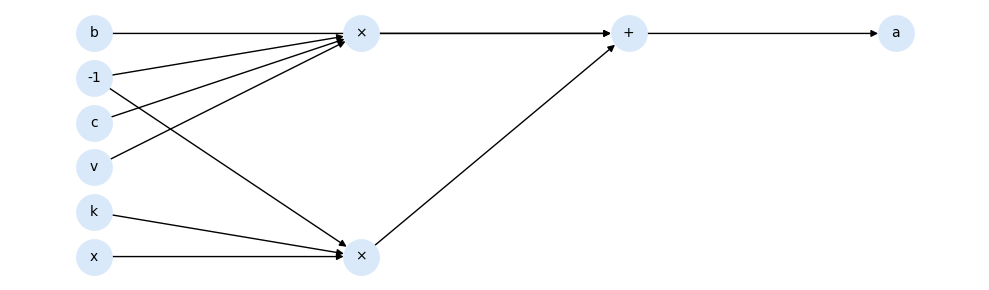

In [1]:
from pathlib import Path
import lab2_analysis as A
import lab2_report as R

output = Path("lab2_results")
output.mkdir(exist_ok=True)
datasets = [A.synthetic(), A.synthetic(damping=0), A.real_data(output / "cache")]
results = []
R.show_model(output)

## 2. Данные

Три опыта: синтетика с трением, контроль без трения и реальные измерения тележки
из Science (2009). В синтетике 600 точек, в реальных данных — 870.
Первые 70% ряда — обучение, последние 30% — проверка. В SMC — 2048 частиц,
seeds фиксированы. Используется локальный архив данных ЛР1.

На графиках верхний ряд — плотности, нижний — накопленные вероятности (ECDF).
Синий — исходные данные, оранжевый — $x=0$, зелёный — $v=0$.

### Синтетика с трением

Трение присутствует по построению. Проверяем, сохранит ли критерий обе ветви.

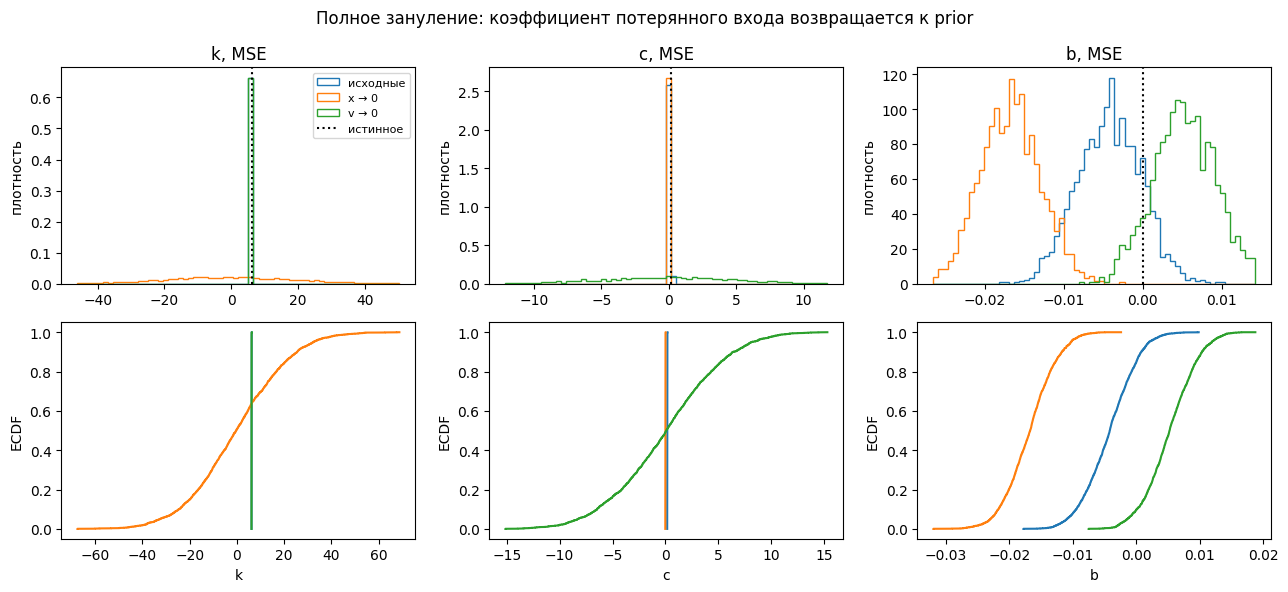

,Ветвь,D KS,"Вклад, %","Изменение RMSE, %",Решение
0,x → a,0.637,100.45,1460.72,сохранить
2,v → a,0.507,7.49,45.91,сохранить


In [2]:
result = A.experiment(datasets[0], n_particles=2048, seed=100)
results.append(result)
R.show_case(result, output / "case_0")

### Контроль без трения

Истинный c равен нулю. Проверяем, удалит ли критерий отсутствующую связь.

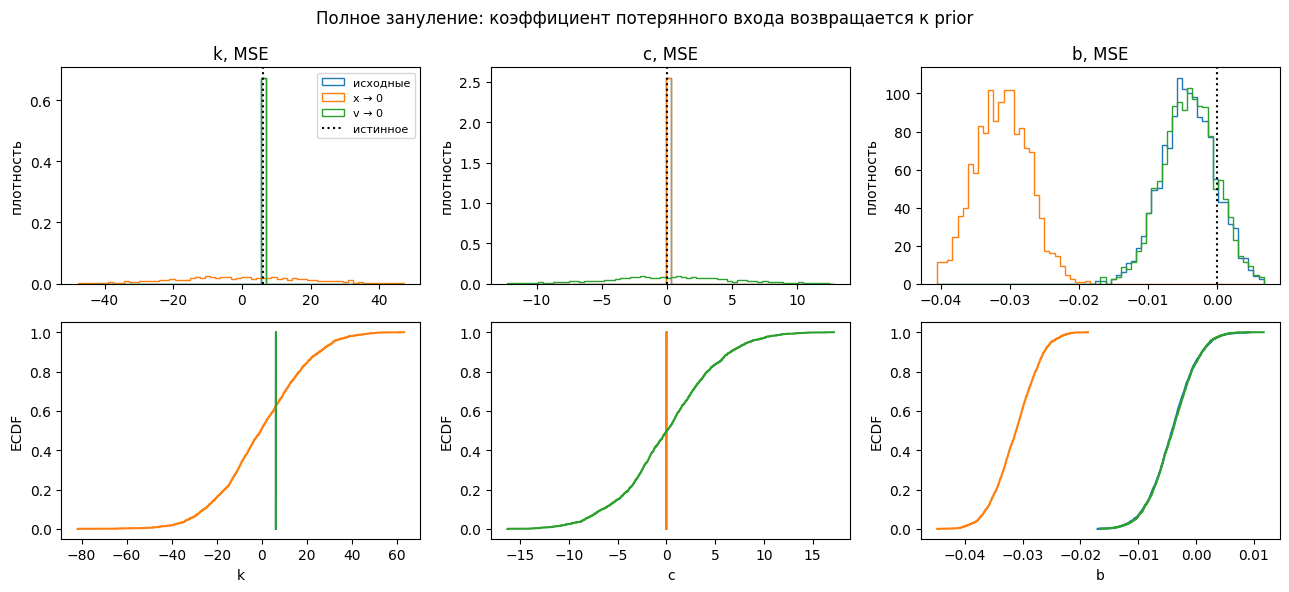

,Ветвь,D KS,"Вклад, %","Изменение RMSE, %",Решение
0,x → a,0.625,100.12,5985.78,сохранить
2,v → a,0.502,0.23,-0.35,удалить


In [3]:
result = A.experiment(datasets[1], n_particles=2048, seed=300)
results.append(result)
R.show_case(result, output / "case_1")

### Реальные данные

Истинные параметры неизвестны. Решение зависит от вклада и ошибки на отложенной части ряда.

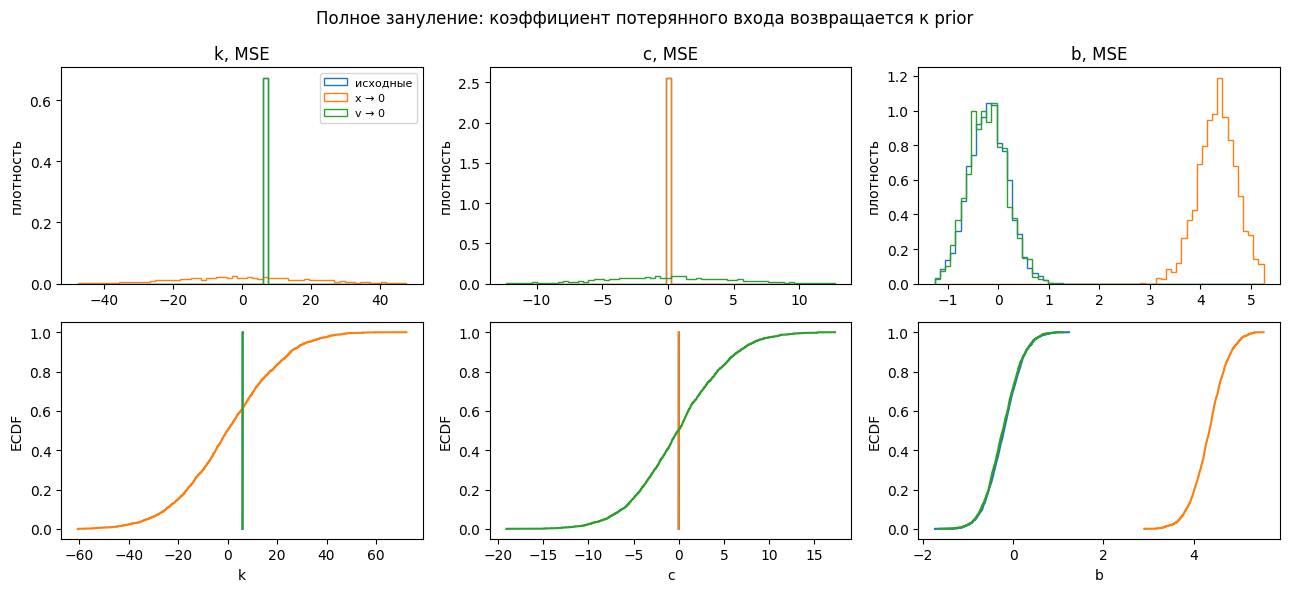

,Ветвь,D KS,"Вклад, %","Изменение RMSE, %",Решение
0,x → a,0.611,100.13,3488.35,сохранить
2,v → a,0.502,0.64,1.13,удалить


In [4]:
result = A.experiment(datasets[2], n_particles=2048, seed=500)
results.append(result)
R.show_case(result, output / "case_2")

## 3. Чувствительность к настройкам

На реальных данных сравним исходные распределения при MSE и MAE в увеличенном масштабе.
Затем посмотрим, как KS меняется с долей занулённых строк: 0 — исходные данные,
1 — полное зануление. Кривые построены для MSE; монотонность не гарантируется.

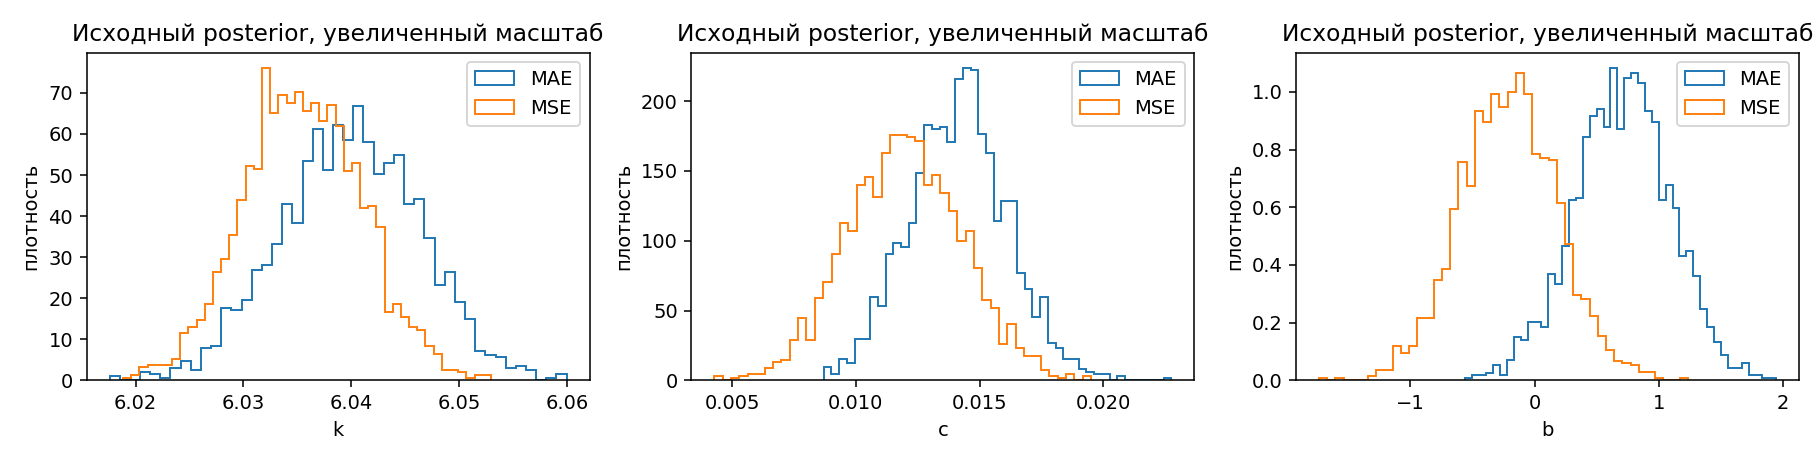

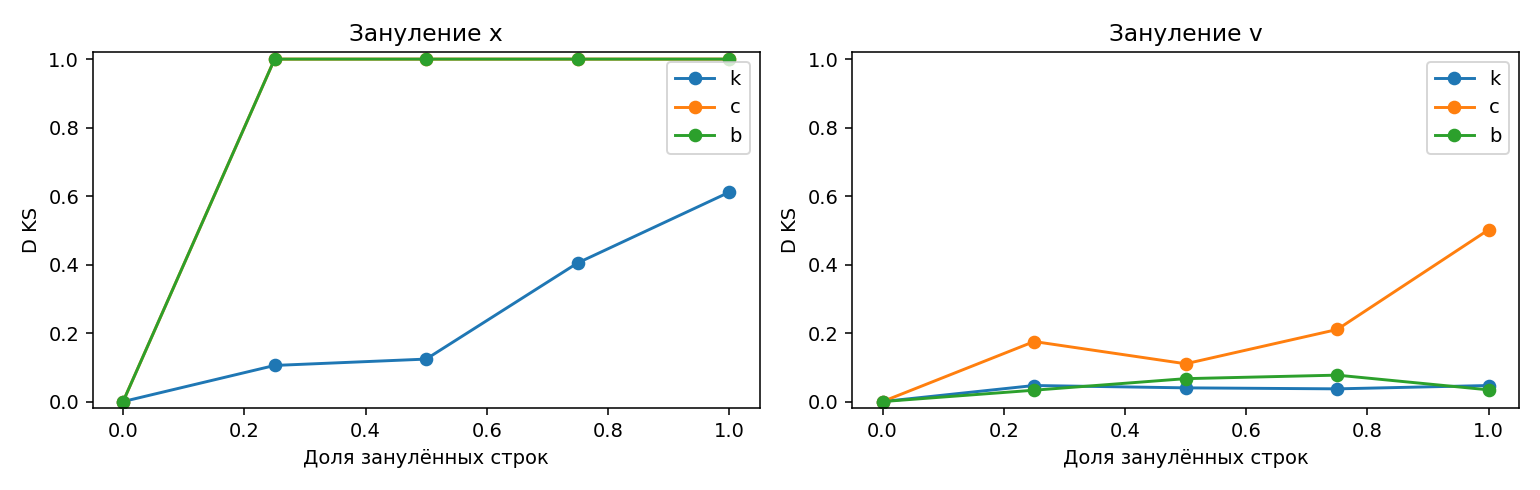

In [5]:
R.show_sensitivity(output / "case_2")

## 4. Итог

Вклад и изменение RMSE ниже приведены в процентах. Таблица показывает результаты
MSE и их согласованность с MAE. Подробная диагностика SMC сохраняется в `lab2_results/`.

In [6]:
summary = R.export_results(results)
R.show_summary(results)

,Данные,Ветвь,D KS,"Вклад, %","Изменение RMSE, %",Решение,Совпадает с MAE
0,Синтетика c=0.18,x → a,0.637,100.45,1460.72,сохранить,да
2,Синтетика c=0.18,v → a,0.507,7.49,45.91,сохранить,да
4,Синтетика c=0,x → a,0.625,100.12,5985.78,сохранить,да
6,Синтетика c=0,v → a,0.502,0.23,-0.35,удалить,да
8,Тележка Science 2009,x → a,0.611,100.13,3488.35,сохранить,да
10,Тележка Science 2009,v → a,0.502,0.64,1.13,удалить,да


Проверка SMC: максимальная ошибка среднего 0.034 стандартного отклонения.


Пружина нужна во всех опытах. Заметное трение в синтетике сохраняется,
отсутствующее трение в контроле удаляется. На реальных данных удаление ветви скорости
укладывается в выбранные допуски для предсказания ускорения.

**Граница вывода:** малое сопротивление может заметно менять затухание за долгое время.
Для расчёта всей траектории нужна отдельная проверка. Переменные состояния не удаляем.
Стандартные p-value KS не используем, поскольку частицы SMC зависимы.

Переиспользованы уравнение, солвер, конструктор графа и загрузчики из `oscillators.py`.
SMC проверен по точному нормальному posterior для MSE.

## Источники

- [Del Moral, Doucet, Jasra (2006): SMC](https://www.stats.ox.ac.uk/~doucet/delmoral_doucet_jasra_sequentialmontecarlosamplersJRSSB.pdf).
- [Schmidt & Lipson (2009): модель и данные](https://doi.org/10.1126/science.1165893).
- [SciPy: KS](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html).

Для защиты: `lab2_latex/lab2_presentation.pdf`; сценарий: `lab2_latex/SPEAKER_NOTES.md`.